# 5. Comparación estadística

Con 28 combinaciones hay 378 pares posibles; probarlos uno a uno con α = 0.05 produciría ~19 falsos
positivos esperados. Por eso se sigue la **secuencia jerárquica** de la guía:

1. **Ómnibus (Friedman)** sobre los 10 pliegues externos → ¿hay alguna diferencia?
2. **Post-hoc de Nemenyi + diagrama de Diferencia Crítica** → qué grupos son equivalentes.
3. Para regresión, sobre las predicciones del hold-out: **MCS** → **Giacomini-White / Clark-West**
   entre finalistas → **Diebold-Mariano (HLN)** mejor vs segundo + **bootstrap estacionario**.
4. **SPA de Hansen** para controlar *data snooping* frente al modelo base del entregable 1.
5. Corrección **Holm / Benjamini-Hochberg** y **tamaños de efecto** (δ de Cliff, d de Cohen).
6. **IC bootstrap BCa** para las métricas principales.

In [1]:
import sys, warnings, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import load_model_data, split_dev_test, xyg, make_preprocessor
from src.models import MODEL_ORDER
from src.nested_cv import collect, regression_metrics
from src.stats_tests import (friedman, nemenyi, cd_diagram, model_confidence_set, giacomini_white, clark_west,
                             diebold_mariano, bootstrap_mean_ci, spa_test, holm, benjamini_hochberg,
                             cliffs_delta, cohens_d_paired)
from src.evaluation import bca_ci, rmse, mae, r2
from src.viz import set_style, MODEL_COLORS, SERIES

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

df = load_model_data()
dev, test = split_dev_test(df)
Xt, yt, _ = xyg(test)
res = collect()
fm = pd.read_csv(C.RESULTS_DIR / "fold_rmse_A_estructural.csv", index_col=0)
mt = pd.read_csv(C.RESULTS_DIR / "master_table.csv")
mtA = mt[mt.scenario == "A_estructural"]
print(f"Matriz de pérdidas por pliegue: {fm.shape[0]} pliegues × {fm.shape[1]} combinaciones")

Matriz de pérdidas por pliegue: 10 pliegues × 28 combinaciones


## 5.1 Etapa 1: test de Friedman (28 combinaciones)

In [2]:
fr = friedman(fm)
pd.DataFrame([{"χ²_F": fr["chi2"], "g.l.": fr["df"], "p-valor": fr["p_value"], "F de Iman-Davenport": fr["iman_davenport_F"],
               "p-valor (F)": fr["p_value_F"], "W de Kendall": fr["kendall_W"], "N (pliegues)": fr["N"], "k": fr["k"]}])

,χ²_F,g.l.,p-valor,F de Iman-Davenport,p-valor (F),W de Kendall,N (pliegues),k
0,145.3525,27,0.0000,10.4950,0.0000,0.5383,10,28


**Interpretación.** Se rechaza con claridad la hipótesis de que las 28 combinaciones rinden igual
(χ²_F = 145.4 con 27 g.l., p < 10⁻¹⁵; F de Iman-Davenport = 10.5). La W de Kendall = 0.54 indica una
concordancia moderada-alta entre pliegues: los rankings de los modelos son bastante consistentes de un
pliegue a otro. Se justifica pasar al análisis post-hoc.

## 5.2 Etapa 2: Nemenyi y diagrama de Diferencia Crítica

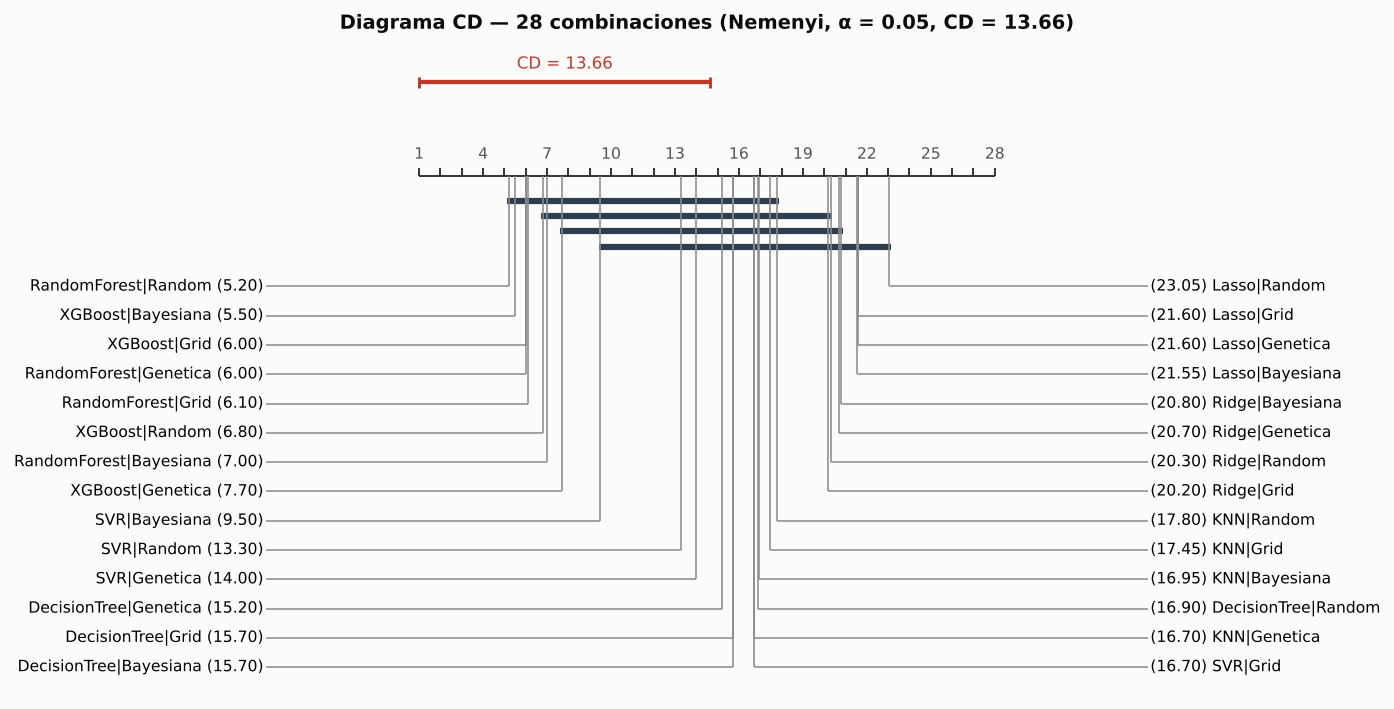

,rango medio
RandomForest|Random,5.2000
XGBoost|Bayesiana,5.5000
XGBoost|Grid,6.0000
RandomForest|Genetica,6.0000
RandomForest|Grid,6.1000
XGBoost|Random,6.8000
RandomForest|Bayesiana,7.0000
XGBoost|Genetica,7.7000
SVR|Bayesiana,9.5000
SVR|Random,13.3000


In [3]:
cd, P = nemenyi(fr["avg_ranks"], fr["N"])
ax = cd_diagram(fr["avg_ranks"], cd, title=f"Diagrama CD — 28 combinaciones (Nemenyi, α = 0.05, CD = {cd:.2f})")
plt.tight_layout()
plt.savefig(C.FIG_DIR / "cd_28.png", dpi=150, bbox_inches="tight")
fr["avg_ranks"].rename("rango medio").to_frame().head(10)

,nivel,χ²,p,W de Kendall,CD
0,7 modelos,34.4571,0.0000,0.5743,2.8483
1,4 optimizadores,0.6382,0.8876,0.0030,0.5606


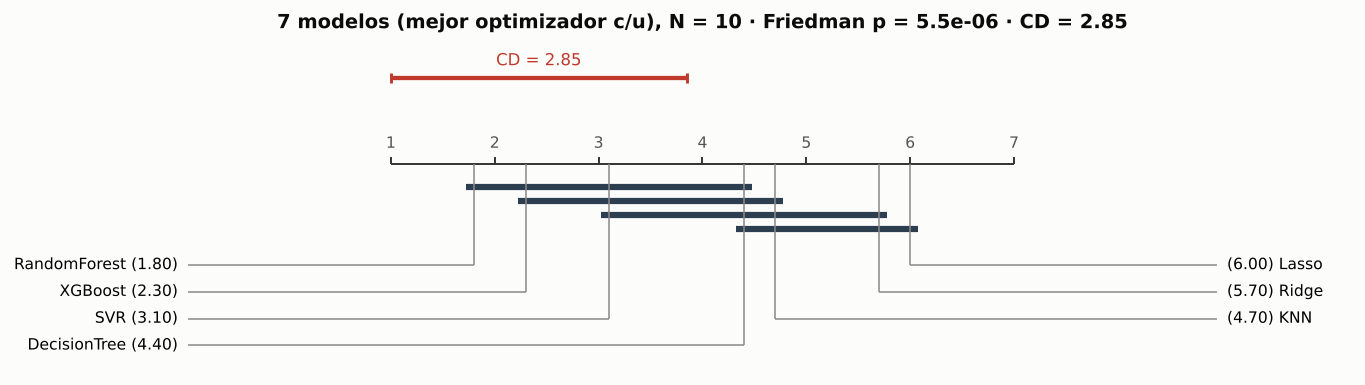

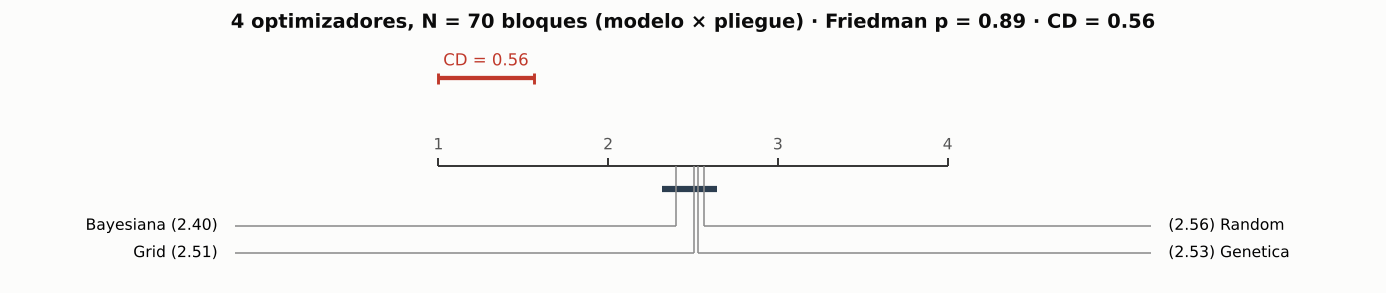

,RandomForest,XGBoost,SVR,DecisionTree,KNN,Ridge,Lasso
RandomForest,1.0000,0.9986,0.8303,0.1004,0.0428,0.0011,0.0003
XGBoost,0.9986,1.0000,0.9821,0.3098,0.1649,0.0079,0.0025
SVR,0.8303,0.9821,1.0000,0.8303,0.6455,0.1004,0.0428
DecisionTree,0.1004,0.3098,0.8303,1.0000,0.9999,0.8303,0.6455
KNN,0.0428,0.1649,0.6455,0.9999,1.0000,0.9460,0.8303
Ridge,0.0011,0.0079,0.1004,0.8303,0.9460,1.0000,0.9999
Lasso,0.0003,0.0025,0.0428,0.6455,0.8303,0.9999,1.0000


In [4]:
# Nivel de modelo: mejor optimizador de cada modelo (7 tratamientos) y nivel de optimizador (4 tratamientos)
best = mtA.loc[mtA.groupby("model")["outer_rmse_mean"].idxmin()].set_index("model")
cols7 = [f"{m}|{best.loc[m, 'method']}" for m in MODEL_ORDER]
fm7 = fm[cols7].copy()
fm7.columns = MODEL_ORDER
fr7 = friedman(fm7)
cd7, P7 = nemenyi(fr7["avg_ranks"], fr7["N"])
# optimizadores: bloques = modelo × pliegue (70 bloques)
long = fm.stack().rename("rmse").reset_index()
long.columns = ["fold", "combo", "rmse"]
long[["model", "method"]] = long["combo"].str.split("|", expand=True)
fm4 = long.pivot_table(index=["model", "fold"], columns="method", values="rmse")[["Grid", "Random", "Bayesiana", "Genetica"]]
fr4 = friedman(fm4)
cd4, P4 = nemenyi(fr4["avg_ranks"], fr4["N"])
cd_diagram(fr7["avg_ranks"], cd7, title=f"7 modelos (mejor optimizador c/u), N = 10 · Friedman p = {fr7['p_value']:.2g} · CD = {cd7:.2f}")
plt.tight_layout()
plt.savefig(C.FIG_DIR / "cd_models.png", dpi=150, bbox_inches="tight")
cd_diagram(fr4["avg_ranks"], cd4, title=f"4 optimizadores, N = 70 bloques (modelo × pliegue) · Friedman p = {fr4['p_value']:.2g} · CD = {cd4:.2f}")
plt.tight_layout()
plt.savefig(C.FIG_DIR / "cd_methods.png", dpi=150, bbox_inches="tight")
display(pd.DataFrame([{"nivel": "7 modelos", "χ²": fr7["chi2"], "p": fr7["p_value"], "W de Kendall": fr7["kendall_W"], "CD": cd7},
                      {"nivel": "4 optimizadores", "χ²": fr4["chi2"], "p": fr4["p_value"], "W de Kendall": fr4["kendall_W"], "CD": cd4}]))
ranks_out = {"combos": fr["avg_ranks"].to_dict(), "cd_combos": cd, "models": fr7["avg_ranks"].to_dict(), "cd_models": cd7,
             "methods": fr4["avg_ranks"].to_dict(), "cd_methods": cd4,
             "friedman": {k: {kk: (float(vv) if not isinstance(vv, pd.Series) else None) for kk, vv in v.items() if kk != "avg_ranks"}
                          for k, v in {"combos": fr, "models": fr7, "methods": fr4}.items()}}
json.dump(ranks_out, open(C.RESULTS_DIR / "friedman_nemenyi.json", "w"), indent=1)
P7.round(4)

**Interpretación.**

- **28 combinaciones.** Con k = 28 y solo N = 10 pliegues la diferencia crítica es enorme (CD = 13.7 rangos):
  Nemenyi es conservador cuando hay muchos tratamientos y pocos bloques. Solo se separan los extremos: las
  combinaciones de Random Forest y XGBoost (rangos 5.2–7.7) son significativamente mejores que las de
  Ridge y Lasso (rangos 20.2–23.1). Todo lo intermedio forma grupos solapados.
- **7 modelos (mejor optimizador de cada uno).** Friedman p = 5.5 × 10⁻⁶, W = 0.57, CD = 2.85.
  Random Forest (1.8) y XGBoost (2.3) superan significativamente a Ridge y Lasso (p Nemenyi ≤ 0.008), y Random
  Forest también a KNN (p = 0.043). Random Forest, XGBoost y SVR **no se distinguen** entre sí
  (p ≥ 0.83).
- **4 optimizadores (70 bloques modelo × pliegue).** Friedman p = 0.89 y W = 0.003: **no hay evidencia de
  que el optimizador cambie el desempeño externo**. Los rangos medios son casi idénticos (Bayesiana 2.40,
  Grid 2.51, Genética 2.53, Random 2.56) y caben dentro de la CD = 0.56.

Esto matiza el capítulo 2: la Bayesiana encuentra mejores óptimos **internos** con el mismo presupuesto, pero
con 30 evaluaciones todos los métodos llegan a una región suficientemente buena y la diferencia queda por
debajo del ruido de la partición. La decisión que más importa es la **familia de modelo**.

## 5.3 Regresión: Model Confidence Set sobre el hold-out

Pérdida = error cuadrático de cada uno de los 28 modelos finales sobre los 749 registros de prueba
(ordenados por activo y año). MCS con estadístico T_max, bootstrap estacionario (bloque medio ≈ n^{1/3})
y α = 0.10. Se incluyen también las líneas base para verificar que el procedimiento las expulsa.

In [5]:
from sklearn.dummy import DummyRegressor
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline

Xd, yd, _ = xyg(dev)
base_pred = {
    "Dummy|—": Pipeline([("prep", make_preprocessor()), ("m", DummyRegressor())]).fit(Xd, yd).predict(Xt),
    "SVR lineal (E1)|—": Pipeline([("prep", make_preprocessor()), ("m", SVR(kernel="linear"))]).fit(Xd, yd).predict(Xt),
}
preds = {f"{r['model']}|{r['method']}": r["pred"] for r in res if r["scenario"] == "A_estructural" and r["fold"] == "final"}
preds_all = {**preds, **base_pred}
losses = pd.DataFrame({k: (yt - v) ** 2 for k, v in preds_all.items()})
mcs = model_confidence_set(losses, alpha=0.10, B=2000)
mcs["RMSE prueba"] = np.sqrt(mcs["mean_loss"])
mcs.to_csv(C.RESULTS_DIR / "mcs.csv", index=False)
mcs[["model", "RMSE prueba", "p_mcs", "in_mcs", "elim_order"]].head(15)

,model,RMSE prueba,p_mcs,in_mcs,elim_order
0,XGBoost|Random,1.5958,1.0000,True,30
1,XGBoost|Bayesiana,1.6235,0.7755,True,29
2,XGBoost|Grid,1.6481,0.7755,True,28
3,RandomForest|Bayesiana,1.6544,0.7755,True,27
4,RandomForest|Genetica,1.6993,0.6725,True,26
5,XGBoost|Genetica,1.7097,0.6725,True,25
6,RandomForest|Random,1.7171,0.6725,True,24
7,RandomForest|Grid,1.7212,0.5060,True,23
8,DecisionTree|Random,1.9208,0.5060,True,22
9,DecisionTree|Genetica,1.9326,0.3880,True,21


**Interpretación.** Con α = 0.10 el conjunto de confianza retiene **15 de los 30** modelos: las 8 combinaciones de
XGBoost y Random Forest (p_MCS ≥ 0.51), los 4 árboles de decisión, KNN-Random y dos SVR. Quedan fuera todos los
Ridge y Lasso, el SVR lineal del entregable 1 y el Dummy (p_MCS ≤ 0.005).

El MCS es amplio porque el hold-out tiene fuerte dependencia dentro de cada activo (cap. 4): el bootstrap
estacionario por bloques reconoce que 749 filas equivalen a muchas menos observaciones independientes (139
activos), lo que ensancha la incertidumbre. Aun así, el mensaje es nítido: **los modelos lineales son
significativamente peores** y los ensambles encabezan el conjunto de confianza (XGBoost-Random con p = 1).

## 5.4 Comparaciones dirigidas: Giacomini-White y Clark-West

- **Giacomini-White (condicional, instrumentos 1 y d_{t−1})** entre los finalistas del MCS de familias
  distintas (modelos no anidados).
- **Clark-West** para pares **anidados**:
  (i) escenario A ⊂ escenario B (B agrega `BrentDifferential` al mismo modelo);
  (ii) Dummy (solo intercepto) ⊂ Ridge.
- Los p-valores de todas las comparaciones dirigidas se ajustan por Holm y por Benjamini-Hochberg.

In [6]:
in_set = mcs[mcs.in_mcs]["model"].tolist()
fam_best = []
for k in in_set:
    fam = k.split("|")[0]
    if fam not in [f.split("|")[0] for f in fam_best]:
        fam_best.append(k)
finalists = fam_best[:4] if len(fam_best) >= 2 else mcs["model"].head(3).tolist()
print("Finalistas (mejor de cada familia dentro del MCS):", finalists)

rows = []
for i in range(len(finalists)):
    for j in range(i + 1, len(finalists)):
        a, b = finalists[i], finalists[j]
        gw = giacomini_white(yt - preds_all[a], yt - preds_all[b], conditional=True)
        rows.append({"prueba": "Giacomini-White (condicional)", "modelo A": a, "modelo B": b,
                     "estadístico": gw["gw"], "p crudo": gw["p_value"],
                     "dif. media pérdida (A−B)": gw["mean_loss_diff"]})
# Clark-West (i): mismo mejor modelo, escenario A (pequeño) vs B (grande, + BD)
bm = best["outer_rmse_mean"].idxmin()
mtB = mt[mt.scenario == "B_con_BD"].set_index("model")
predB = next(r["pred"] for r in res if r["scenario"] == "B_con_BD" and r["model"] == bm and r["fold"] == "final")
predA_bayes = next(r["pred"] for r in res if r["scenario"] == "A_estructural" and r["model"] == bm and r["method"] == "Bayesiana" and r["fold"] == "final")
cw1 = clark_west(yt, predA_bayes, predB)
rows.append({"prueba": "Clark-West (anidados)", "modelo A": f"{bm}|Bayesiana (A, sin BD)", "modelo B": f"{bm}|Bayesiana (B, con BD)",
             "estadístico": cw1["cw"], "p crudo": cw1["p_value"],
             "dif. media pérdida (A−B)": float(np.mean((yt - predA_bayes) ** 2 - (yt - predB) ** 2))})
ridge_key = f"Ridge|{best.loc['Ridge', 'method']}"
cw2 = clark_west(yt, base_pred["Dummy|—"], preds_all[ridge_key])
rows.append({"prueba": "Clark-West (anidados)", "modelo A": "Dummy|—", "modelo B": ridge_key, "estadístico": cw2["cw"],
             "p crudo": cw2["p_value"], "dif. media pérdida (A−B)": float(np.mean((yt - base_pred["Dummy|—"]) ** 2 - (yt - preds_all[ridge_key]) ** 2))})
directed = pd.DataFrame(rows)
directed["p Holm"] = holm(directed["p crudo"])
directed["p BH"] = benjamini_hochberg(directed["p crudo"])
directed.to_csv(C.RESULTS_DIR / "directed_tests.csv", index=False)
directed

Finalistas (mejor de cada familia dentro del MCS): ['XGBoost|Random', 'RandomForest|Bayesiana', 'DecisionTree|Random', 'KNN|Random']


,prueba,modelo A,modelo B,estadístico,p crudo,dif. media pérdida (A−B),p Holm,p BH
0,Giacomini-White (condicional),XGBoost|Random,RandomForest|Bayesiana,7.8956,0.0193,-0.1904,0.0772,0.0260
1,Giacomini-White (condicional),XGBoost|Random,DecisionTree|Random,7.8742,0.0195,-1.1430,0.0772,0.0260
2,Giacomini-White (condicional),XGBoost|Random,KNN|Random,12.4600,0.0020,-1.7559,0.0098,0.0039
3,Giacomini-White (condicional),RandomForest|Bayesiana,DecisionTree|Random,5.8458,0.0538,-0.9527,0.1076,0.0615
4,Giacomini-White (condicional),RandomForest|Bayesiana,KNN|Random,12.9541,0.0015,-1.5655,0.0092,0.0039
5,Giacomini-White (condicional),DecisionTree|Random,KNN|Random,4.3433,0.1140,-0.6128,0.1140,0.1140
6,Clark-West (anidados),"RandomForest|Bayesiana (A, sin BD)","RandomForest|Bayesiana (B, con BD)",9.8590,0.0000,1.3169,0.0000,0.0000
7,Clark-West (anidados),Dummy|—,Ridge|Random,14.1640,0.0000,26.7633,0.0000,0.0000


**Interpretación.**

- **Giacomini-White (condicional).** XGBoost tiene menor pérdida media que Random Forest (−0.19), y el test
  condicional da p = 0.019; tras Holm (0.077) la diferencia **no** es significativa al 5 %, aunque sí con
  control de FDR (BH = 0.026). Ambos ensambles superan a KNN con p ajustado < 0.01. El rechazo condicional
  entre XGBoost y RF se debe en parte a que la diferencia de pérdidas es predecible con su propio rezago
  (dependencia dentro de cada activo): un modelo es mejor en ciertos activos de forma persistente.
- **Clark-West, escenario A ⊂ B.** Agregar `BrentDifferential` mejora la precisión de forma muy significativa
  (CW = 9.9, p < 10⁻¹⁵): reduce el error cuadrático medio en 1.32 (USD/Bbl)². Es la confirmación formal de que
  BD aporta información, como era de esperar al ser un sumando del target.
- **Clark-West, Dummy ⊂ Ridge.** Hasta el modelo lineal supera con creces a la media (CW = 14.2).
  Se usa CW (y no DM) en estos pares porque son modelos **anidados**, donde DM está sesgado a favor del
  modelo grande.

## 5.5 Diebold-Mariano (HLN) mejor vs segundo + bootstrap estacionario

In [7]:
order = mcs.sort_values("mean_loss")["model"].tolist()
first, second = order[0], order[1]
e1, e2 = yt - preds_all[first], yt - preds_all[second]
dm = diebold_mariano(e1, e2, h=1)
d = e1 ** 2 - e2 ** 2
ci = bootstrap_mean_ci(d, B=4000)
cd_, mag = cohens_d_paired(d)
dm_tbl = pd.DataFrame([{"modelo 1 (mejor)": first, "modelo 2 (segundo)": second,
                        "dif. media pérdida (1−2)": dm["mean_loss_diff"], "IC 95 % bootstrap estacionario": f"[{ci[0]:.3f}, {ci[1]:.3f}]",
                        "DM (HLN)": dm["dm_hln"], "p-valor": dm["p_value"], "d de Cohen": cd_, "magnitud": mag}])
# confirmación adicional: mejor vs SVR lineal del entregable 1
e3 = yt - base_pred["SVR lineal (E1)|—"]
dm2 = diebold_mariano(e1, e3)
d2 = e1 ** 2 - e3 ** 2
ci2 = bootstrap_mean_ci(d2, B=4000)
cd2, mag2 = cohens_d_paired(d2)
dm_tbl = pd.concat([dm_tbl, pd.DataFrame([{"modelo 1 (mejor)": first, "modelo 2 (segundo)": "SVR lineal (E1)",
                                           "dif. media pérdida (1−2)": dm2["mean_loss_diff"], "IC 95 % bootstrap estacionario": f"[{ci2[0]:.3f}, {ci2[1]:.3f}]",
                                           "DM (HLN)": dm2["dm_hln"], "p-valor": dm2["p_value"], "d de Cohen": cd2, "magnitud": mag2}])])
dm_tbl["p Holm (2 pruebas)"] = holm(dm_tbl["p-valor"])
dm_tbl.to_csv(C.RESULTS_DIR / "dm_tests.csv", index=False)
dm_tbl

,modelo 1 (mejor),modelo 2 (segundo),dif. media pérdida (1−2),IC 95 % bootstrap estacionario,DM (HLN),p-valor,d de Cohen,magnitud,p Holm (2 pruebas)
0,XGBoost|Random,XGBoost|Bayesiana,-0.0893,"[-0.265, 0.071]",-1.3814,0.1676,-0.0505,despreciable,0.1676
0,XGBoost|Random,SVR lineal (E1),-4.8460,"[-7.751, -2.466]",-4.1238,0.0000,-0.1507,despreciable,0.0001


**Interpretación.**

- **Mejor vs segundo (XGBoost-Random vs XGBoost-Bayesiana):** diferencia de pérdida media −0.09 con IC 95 %
  por bootstrap estacionario [−0.27, 0.07] que contiene el cero; DM-HLN = −1.38, p = 0.17. **No hay
  diferencia significativa**: el "mejor" modelo en prueba es intercambiable con el segundo, consistente con
  el resultado de Friedman entre optimizadores.
- **Mejor vs modelo base del entregable 1 (SVR lineal sin BD):** la diferencia es grande y significativa
  (−4.85 (USD/Bbl)², IC [−7.75, −2.47], p < 0.001 tras Holm). El d de Cohen es pequeño (−0.15) porque las
  diferencias de error cuadrático tienen colas muy pesadas (unos pocos activos concentran errores grandes) y
  la desviación estándar es enorme; en términos prácticos la mejora es relevante: el RMSE baja de 2.72 a 1.60
  USD/Bbl (−41 %). Este caso muestra por qué la guía pide tamaños de efecto: la magnitud depende de la escala
  en que se mide.

## 5.6 SPA de Hansen: ¿alguno de los 28 supera genuinamente al modelo base?

Benchmark = SVR lineal del entregable 1 (mismas variables del escenario A). H0: ningún modelo del universo
de 28 tiene menor pérdida esperada que el benchmark. El SPA corrige el *data snooping* de elegir el
mejor entre muchos.

In [8]:
spa = spa_test(losses["SVR lineal (E1)|—"], losses[list(preds)], B=4000)
json.dump(spa, open(C.RESULTS_DIR / "spa.json", "w"), indent=1)
pd.DataFrame([spa])

,p_l,p_c,p_u,t_spa,best_model
0,0.0000,0.0000,0.0000,4.7947,XGBoost|Random


**Interpretación.** Los tres p-valores del SPA (consistente, inferior y superior/Reality Check) son < 0.001:
aun corrigiendo por haber probado 28 combinaciones, **existe al menos un modelo que supera genuinamente** al
SVR lineal del entregable 1. El mejor del universo es XGBoost-Random. La superioridad no es producto del
*data snooping*.

## 5.7 Tamaños de efecto entre modelos (pliegues externos)

δ de Cliff entre los 10 RMSE externos del mejor modelo y los de cada uno de los demás (mejor optimizador
de cada modelo). δ < 0 significa que el mejor modelo tiene RMSE menores.

In [9]:
rows = []
for m in MODEL_ORDER:
    if m == bm:
        continue
    dlt, mg = cliffs_delta(fm7[bm], fm7[m])
    rows.append({"comparación": f"{bm} vs {m}", "RMSE medio mejor": fm7[bm].mean(), "RMSE medio otro": fm7[m].mean(),
                 "δ de Cliff": dlt, "magnitud": mg, "p Nemenyi": P7.loc[bm, m]})
pd.DataFrame(rows).sort_values("δ de Cliff")

,comparación,RMSE medio mejor,RMSE medio otro,δ de Cliff,magnitud,p Nemenyi
2,RandomForest vs Lasso,2.0082,2.7047,-0.7600,grande,0.0003
1,RandomForest vs Ridge,2.0082,2.6832,-0.7400,grande,0.0011
0,RandomForest vs KNN,2.0082,2.6127,-0.5600,grande,0.0428
3,RandomForest vs DecisionTree,2.0082,2.4475,-0.3800,mediano,0.1004
5,RandomForest vs SVR,2.0082,2.1867,-0.2800,pequeño,0.8303
4,RandomForest vs XGBoost,2.0082,2.0573,-0.0400,despreciable,0.9986


**Interpretación.** Random Forest domina a Lasso, Ridge y KNN con efecto **grande** (δ entre −0.56 y −0.76:
en la gran mayoría de pares de pliegues RF tiene menor RMSE), al árbol con efecto mediano (−0.38) y a SVR con
efecto pequeño (−0.28). Frente a XGBoost el efecto es **despreciable** (−0.04). Los tamaños de efecto coinciden
con Nemenyi: las diferencias significativas son además grandes, y las no significativas son pequeñas.

## 5.8 Intervalos de confianza BCa (hold-out)

In [10]:
rows = []
for m in MODEL_ORDER:
    k = f"{m}|{best.loc[m, 'method']}"
    p = preds_all[k]
    for name, fn in [("RMSE", rmse), ("MAE", mae), ("R²", r2)]:
        lo, hi = bca_ci(yt, p, fn, n_resamples=2000)
        rows.append({"Modelo": k, "Métrica": name, "Valor": fn(yt, p), "IC 95 % inferior": lo, "IC 95 % superior": hi})
bca = pd.DataFrame(rows)
bca.to_csv(C.RESULTS_DIR / "bca_ci.csv", index=False)
bca.pivot(index="Modelo", columns="Métrica", values=["Valor", "IC 95 % inferior", "IC 95 % superior"]).swaplevel(axis=1).sort_index(axis=1)

Métrica                            MAE                   ...               R²                             IC 95 % inferior IC 95 % superior  ... IC 95 % superior  ValorModelo                                                   ...                        DecisionTree|Genetica           0.9115           1.1471  ...           0.9134 0.8894KNN|Bayesiana                   1.0964           1.3463  ...           0.8896 0.8659Lasso|Bayesiana                 1.5698           1.8743  ...           0.8239 0.7936RandomForest|Random             0.8762           1.0792  ...           0.9287 0.9127Ridge|Random                    1.5563           1.8688  ...           0.8191 0.7888SVR|Bayesiana                   0.9861           1.2579  ...           0.8875 0.8619XGBoost|Grid                    0.8511           1.0473  ...           0.9352 0.9196[7 rows x 9 columns]

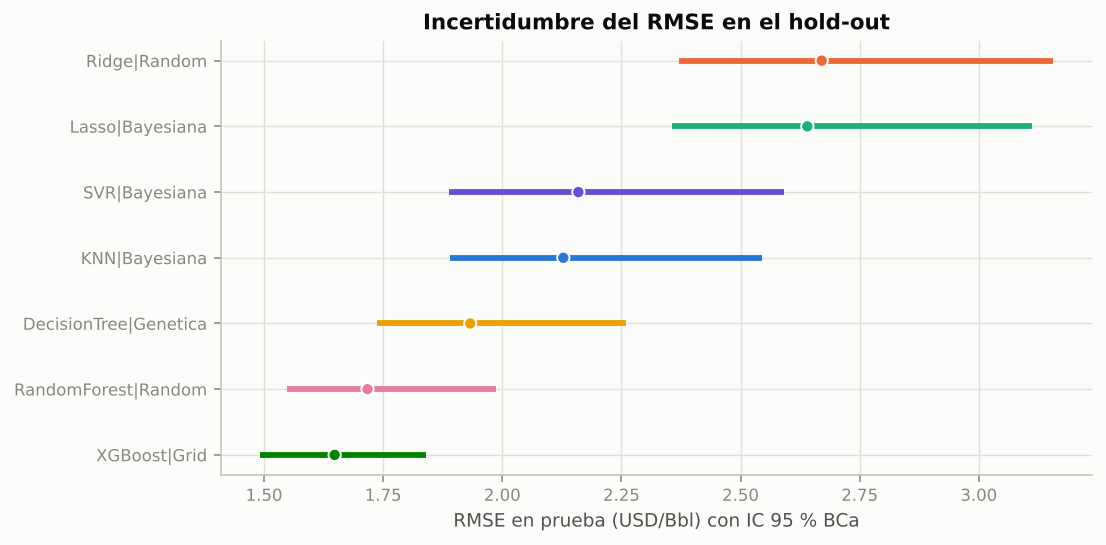

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
b = bca[bca["Métrica"] == "RMSE"].sort_values("Valor")
yy = np.arange(len(b))
ax.hlines(yy, b["IC 95 % inferior"], b["IC 95 % superior"], color=[MODEL_COLORS[k.split("|")[0]] for k in b.Modelo], lw=3)
ax.scatter(b["Valor"], yy, color=[MODEL_COLORS[k.split("|")[0]] for k in b.Modelo], s=40, zorder=3, edgecolor="white")
ax.set_yticks(yy, b.Modelo)
ax.set(xlabel="RMSE en prueba (USD/Bbl) con IC 95 % BCa", title="Incertidumbre del RMSE en el hold-out")
plt.tight_layout()

**Interpretación.** Los IC BCa de XGBoost (RMSE 1.65 [1.49, 1.84]) y Random Forest (1.72 [1.55, 1.99]) se
solapan casi por completo, y ambos quedan por debajo de los de Ridge y Lasso (2.64–2.67, con límites
inferiores ≥ 2.36). Los intervalos son asimétricos (el límite superior está más lejos del valor puntual),
por eso se usa BCa en lugar del percentil simple. Son IC por observación: dado que los errores están
correlacionados dentro de cada activo, deben leerse como una cota inferior de la incertidumbre real.

## 5.9 Síntesis de la evidencia estadística

| Pregunta | Prueba | Resultado |
|---|---|---|
| ¿Difieren las 28 combinaciones? | Friedman | Sí (p < 10⁻¹⁵, W = 0.54) |
| ¿Qué familias difieren? | Nemenyi (7 modelos) | RF y XGBoost > Ridge, Lasso (y RF > KNN); RF ≈ XGBoost ≈ SVR |
| ¿Importa el optimizador? | Friedman (4 optimizadores) | No (p = 0.89) |
| ¿Qué modelos son indistinguibles del mejor en prueba? | MCS (α = 0.10) | 15 de 30; todos los RF/XGBoost dentro, todos los lineales fuera |
| ¿XGBoost vs Random Forest? | GW condicional + Holm | No significativo al 5 % (p Holm = 0.077) |
| ¿Aporta BrentDifferential? | Clark-West (A ⊂ B) | Sí (p < 10⁻¹⁵) |
| ¿Mejor vs segundo? | DM-HLN + bootstrap estacionario | No (p = 0.17; IC contiene 0) |
| ¿Supera algo al modelo base del E1? | SPA de Hansen | Sí (p < 0.001) |
| ¿Magnitud? | δ de Cliff | Grande frente a lineales y KNN; despreciable RF vs XGBoost |

**Conclusión estadística.** Los ensambles de árboles (Random Forest y XGBoost) son el grupo ganador, sin
diferencia demostrable entre ellos. Su ventaja frente a los modelos lineales y al modelo base del primer
entregable es significativa, robusta a comparaciones múltiples y grande en magnitud. El método de optimización
de hiperparámetros no cambia el resultado final con este presupuesto.